# Experiment 10: Low-Resource Neural Machine Translation (`WMT 2026 Indic MT — English → Bodo`)

**Objective:** Implement and compare three Neural Machine Translation (NMT) approaches on the official **WMT 2026 Low-Resource Indic Language Translation (`INDICNE-CORP 2.0`)** dataset for **Category II: English → Bodo (`en → brx`, Devanagari script)**:
1. **Seq2Seq BiGRU + Attention (From Scratch):** Recurrent encoder-decoder with dot-product attention trained solely on the parallel corpus.
2. **Pretrained Multilingual Transformer (Zero-Shot):** `Helsinki-NLP/opus-mt-en-mul` (`MarianMT`) prompted with the target language token `>>brx<<`.
3. **Fine-Tuned Multilingual Transformer (Domain & Language Adapted):** `Helsinki-NLP/opus-mt-en-mul` fine-tuned end-to-end on the WMT 2026 English–Bodo training set.

Models are evaluated with the official WMT metrics: **BLEU**, **ChrF++** (character + word n-gram F-score), **TER** (Translation Edit Rate, lower is better), and **mBERT BERTScore-F1**.

## 10.1 Data Collection & Parallel Corpus Preprocessing (WMT 2026)

In [1]:
import os, re, time, random, unicodedata, urllib.request, warnings, gc
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
warnings.filterwarnings('ignore')
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
os.environ['HF_HUB_DISABLE_XET'] = '1'

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

# Auto-download WMT 2026 Category II English-Bodo parallel corpus if not present locally
XLSX_PATH = Path('English-Bodo_Training_Data_2026.xlsx')
if not XLSX_PATH.exists():
    WMT26_URL = 'https://drive.usercontent.google.com/download?id=11-UK1B2crlayzTgsvHNkEZFedEd7XrLc&export=download&confirm=t'
    urllib.request.urlretrieve(WMT26_URL, XLSX_PATH)

raw_df = pd.read_excel(XLSX_PATH)[['English', 'Bodo']].dropna()

def normalize_pair(s):
    s = unicodedata.normalize('NFC', str(s))
    return re.sub(r'\s+', ' ', s).strip()

raw_df['en'] = raw_df['English'].map(normalize_pair)
raw_df['brx'] = raw_df['Bodo'].map(normalize_pair)
df = raw_df.drop_duplicates(subset=['en', 'brx']).copy()
en_len, brx_len = df['en'].str.split().str.len(), df['brx'].str.split().str.len()
df = df[(en_len.between(2, 50)) & (brx_len.between(2, 50)) & ((en_len / brx_len).between(0.3, 3.0))].reset_index(drop=True)
df[['en', 'brx']].to_csv('wmt26_en_bodo_clean.csv', index=False, encoding='utf-8-sig')

from sklearn.model_selection import train_test_split
train_df, temp_df = train_test_split(df, test_size=1000, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=500, random_state=SEED)
train_df, val_df, test_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True), test_df.reset_index(drop=True)

print(f'Raw pairs: {len(raw_df):,} -> Cleaned: {len(df):,} | Train: {len(train_df):,} | Val: {len(val_df)} | Test: {len(test_df)}')
train_df[['en', 'brx']].head(3)

Device: cuda | NVIDIA GeForce RTX 4060 Laptop GPU


Raw pairs: 15,214 -> Cleaned: 12,762 | Train: 11,762 | Val: 500 | Test: 500


,en,brx
0,Darkness often precedes a spiritual breakthrough.,खोमसिआ गोबां समावनो मोनसे इसोरारि जाफुंसारनायन...
1,Carl Lewis's versatility in track and field ev...,ट्रेक आरो फील्ड आयदाफोराव कार्ल लुईसनि गोबां र...
2,"Spanish midfielder Roy, who plays for Manchest...",मन्वेस्टर सिटिनि जानाने गेलेग्रा स्पेननि मिडफि...


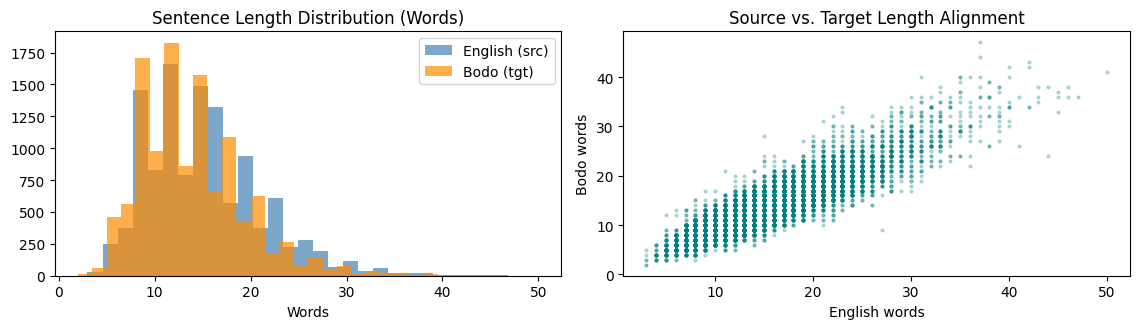

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.4))
ax[0].hist(train_df['en'].str.split().str.len(), bins=30, alpha=0.7, label='English (src)', color='steelblue')
ax[0].hist(train_df['brx'].str.split().str.len(), bins=30, alpha=0.7, label='Bodo (tgt)', color='darkorange')
ax[0].set(title='Sentence Length Distribution (Words)', xlabel='Words'); ax[0].legend()
ax[1].scatter(train_df['en'].str.split().str.len(), train_df['brx'].str.split().str.len(), s=4, alpha=0.25, color='teal')
ax[1].set(title='Source vs. Target Length Alignment', xlabel='English words', ylabel='Bodo words')
plt.tight_layout(); plt.show()

## 10.2 Model 1: Seq2Seq GRU with Attention (From Scratch)

A lightweight recurrent baseline built from scratch: an embedding + GRU encoder summarizes the English sentence into hidden states $H$, and a GRU decoder attends over $H$ via scaled dot-product attention $\alpha_t = \text{softmax}(s_t H^\top)$ at each step to predict Bodo tokens.

In [3]:
PAD, BOS, EOS, UNK, MAX_TOK = 0, 1, 2, 3, 40

def tok_words(s):
    # Preserve Devanagari combining vowel matras (Mn/Mc) inside words; split only on punctuation/symbols & whitespace
    return ''.join(' ' if unicodedata.category(ch)[0] in 'PS' else ch for ch in s.lower()).split()

def build_vocab(texts, max_vocab=8000):
    itos = ['<pad>', '<bos>', '<eos>', '<unk>'] + [w for w, _ in Counter(w for t in texts for w in tok_words(t)).most_common(max_vocab - 4)]
    return itos, {w: i for i, w in enumerate(itos)}

src_itos, src_stoi = build_vocab(train_df['en'])
tgt_itos, tgt_stoi = build_vocab(train_df['brx'])

def vec_split(frame):
    S = torch.zeros((len(frame), MAX_TOK), dtype=torch.long)
    T = torch.zeros((len(frame), MAX_TOK), dtype=torch.long)
    for i, (e, b) in enumerate(zip(frame['en'], frame['brx'])):
        s_ids = [src_stoi.get(w, UNK) for w in tok_words(e)[:MAX_TOK - 2]] + [EOS]
        t_ids = [BOS] + [tgt_stoi.get(w, UNK) for w in tok_words(b)[:MAX_TOK - 2]] + [EOS]
        S[i, :len(s_ids)] = torch.tensor(s_ids); T[i, :len(t_ids)] = torch.tensor(t_ids)
    return TensorDataset(S, T)

seq_train = DataLoader(vec_split(train_df), batch_size=128, shuffle=True)

class AttnSeq2Seq(nn.Module):
    def __init__(self, sv, tv, d=192):
        super().__init__()
        self.src_emb = nn.Embedding(sv, d, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(tv, d, padding_idx=PAD)
        self.enc = nn.GRU(d, d, batch_first=True)
        self.dec = nn.GRU(d, d, batch_first=True)
        self.out = nn.Linear(2 * d, tv)

    def forward(self, src, tgt_in):
        enc_out, h = self.enc(self.src_emb(src))
        dec_out, _ = self.dec(self.tgt_emb(tgt_in), h)
        scores = torch.bmm(dec_out, enc_out.transpose(1, 2)).masked_fill((src == PAD).unsqueeze(1), -1e9)
        ctx = torch.bmm(scores.softmax(-1), enc_out)
        return self.out(torch.cat([dec_out, ctx], dim=-1))

    @torch.no_grad()
    def translate(self, texts):
        self.eval(); hyps = []
        for e in texts:
            s_ids = [src_stoi.get(w, UNK) for w in tok_words(e)[:MAX_TOK - 2]] + [EOS]
            src = torch.tensor([s_ids], device=device)
            enc_out, h = self.enc(self.src_emb(src))
            tok_id, words = BOS, []
            for _ in range(MAX_TOK):
                dec_out, h = self.dec(self.tgt_emb(torch.tensor([[tok_id]], device=device)), h)
                ctx = torch.bmm(torch.bmm(dec_out, enc_out.transpose(1, 2)).softmax(-1), enc_out)
                tok_id = self.out(torch.cat([dec_out, ctx], dim=-1))[0, 0].argmax().item()
                if tok_id == EOS:
                    break
                if tok_id not in (PAD, BOS, UNK):
                    words.append(tgt_itos[tok_id])
            hyps.append(' '.join(words))
        return hyps

torch.manual_seed(SEED)
seq2seq = AttnSeq2Seq(len(src_itos), len(tgt_itos)).to(device)
opt = torch.optim.Adam(seq2seq.parameters(), lr=2e-3)
loss_fn = nn.CrossEntropyLoss(ignore_index=PAD)

t0 = time.time()
for ep in range(1, 9):
    seq2seq.train(); tot = 0.0
    for s, t in seq_train:
        s, t = s.to(device), t.to(device)
        opt.zero_grad()
        logits = seq2seq(s, t[:, :-1])
        loss = loss_fn(logits.reshape(-1, logits.size(-1)), t[:, 1:].reshape(-1))
        loss.backward(); nn.utils.clip_grad_norm_(seq2seq.parameters(), 1.0); opt.step()
        tot += loss.item()
    if ep in (1, 4, 8):
        print(f'Seq2Seq Epoch {ep}/8 | loss = {tot / len(seq_train):.4f}')
seq_time = time.time() - t0
hyps_seq2seq = seq2seq.translate(test_df['en'].tolist())
del seq2seq; gc.collect(); torch.cuda.empty_cache()
print(f'Trained Seq2Seq + Attention in {seq_time:.1f}s | Sample output:', hyps_seq2seq[0])

Seq2Seq Epoch 1/8 | loss = 6.7935


Seq2Seq Epoch 4/8 | loss = 3.8562


Seq2Seq Epoch 8/8 | loss = 1.8749


Trained Seq2Seq + Attention in 24.4s | Sample output: मोनसे गोहोगोरा


## 10.3 Model 2 & Model 3: Pretrained vs. Fine-Tuned Multilingual Transformer (`MarianMT`)

`Helsinki-NLP/opus-mt-en-mul` is a 6-layer encoder-decoder Transformer (`~75M` parameters) pretrained across 100+ target languages using SentencePiece subwords and sentence-initial language tokens (`>>brx<<` for Bodo). We first evaluate it **zero-shot**, then **fine-tune** it for 4 epochs on the WMT 2026 English–Bodo training split.

In [4]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup, logging as hf_logging
hf_logging.set_verbosity_error()

NMT_ID, REV = 'Helsinki-NLP/opus-mt-en-mul', 'refs/pr/2'
nmt_tok = AutoTokenizer.from_pretrained(NMT_ID, revision=REV)
nmt_model = AutoModelForSeq2SeqLM.from_pretrained(NMT_ID, revision=REV, use_safetensors=True).to(device)

@torch.no_grad()
def translate_marian(model, texts, bs=32):
    model.eval(); outs = []
    tagged = [f'>>brx<< {t}' for t in texts]
    for i in range(0, len(tagged), bs):
        enc = nmt_tok(tagged[i:i + bs], truncation=True, padding=True, max_length=64, return_tensors='pt').to(device)
        ids = model.generate(**enc, num_beams=4, max_length=64, early_stopping=True)
        outs.extend(nmt_tok.batch_decode(ids, skip_special_tokens=True))
    return [o.strip() for o in outs]

# 1. Zero-shot evaluation on WMT 2026 Bodo test split
t0 = time.time()
hyps_zeroshot = translate_marian(nmt_model, test_df['en'].tolist())
zs_time = time.time() - t0
print(f'Zero-shot MarianMT decoded 500 sentences in {zs_time:.1f}s | Sample:', hyps_zeroshot[0])

Zero-shot MarianMT decoded 500 sentences in 15.4s | Sample: L’enseignement de meditación, illeen tolke demasiado relacione.


In [5]:
# 2. Fine-tune MarianMT on WMT 2026 English-Bodo parallel training set
src_enc = nmt_tok([f'>>brx<< {t}' for t in train_df['en']], truncation=True, padding='max_length', max_length=64, return_tensors='pt')
tgt_enc = nmt_tok(text_target=train_df['brx'].tolist(), truncation=True, padding='max_length', max_length=64, return_tensors='pt')
labels_tensor = tgt_enc['input_ids'].clone()
labels_tensor[labels_tensor == nmt_tok.pad_token_id] = -100

ft_loader = DataLoader(TensorDataset(src_enc['input_ids'], src_enc['attention_mask'], labels_tensor), batch_size=32, shuffle=True)
EPOCHS_FT = 4
opt = torch.optim.AdamW(nmt_model.parameters(), lr=5e-5, weight_decay=0.01)
sched = get_linear_schedule_with_warmup(opt, int(0.1 * EPOCHS_FT * len(ft_loader)), EPOCHS_FT * len(ft_loader))

t0 = time.time()
for ep in range(1, EPOCHS_FT + 1):
    nmt_model.train(); tot = 0.0
    for ids, mask, lab in ft_loader:
        opt.zero_grad()
        with torch.autocast('cuda', dtype=torch.bfloat16, enabled=(device.type == 'cuda')):
            loss = nmt_model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=lab.to(device)).loss
        loss.backward(); nn.utils.clip_grad_norm_(nmt_model.parameters(), 1.0); opt.step(); sched.step()
        tot += loss.item()
    print(f'Fine-Tune Epoch {ep}/{EPOCHS_FT} | train loss = {tot / len(ft_loader):.4f}')
ft_time = time.time() - t0

hyps_finetuned = translate_marian(nmt_model, test_df['en'].tolist())
del nmt_model; gc.collect(); torch.cuda.empty_cache()
print(f'Fine-tuned MarianMT in {ft_time:.1f}s | Sample:', hyps_finetuned[0])

Fine-Tune Epoch 1/4 | train loss = 2.5687


Fine-Tune Epoch 2/4 | train loss = 1.0380


Fine-Tune Epoch 3/4 | train loss = 0.7727


Fine-Tune Epoch 4/4 | train loss = 0.6640


Fine-tuned MarianMT in 200.9s | Sample: ध्याननि हुदाया गावजों गोथौ सोमोन्दो लाबोयो।


## 10.4 Comparative Evaluation (`BLEU`, `ChrF++`, `TER`, `mBERT BERTScore`)

In [6]:
import sacrebleu
from bert_score import score as bert_score

refs = test_df['brx'].tolist()
systems = {
    'Seq2Seq + Attention (Scratch)': (hyps_seq2seq,   seq_time),
    'MarianMT (Zero-Shot >>brx<<)':  (hyps_zeroshot,  zs_time),
    'MarianMT (WMT26 Fine-Tuned)':   (hyps_finetuned, ft_time),
}

rows = {}
for name, (hyps, elapsed) in systems.items():
    bleu = sacrebleu.corpus_bleu(hyps, [refs]).score
    chrf = sacrebleu.corpus_chrf(hyps, [refs], word_order=2).score
    ter  = sacrebleu.corpus_ter(hyps, [refs]).score
    _, _, F = bert_score(hyps, refs, model_type='google-bert/bert-base-multilingual-cased',
                         num_layers=9, batch_size=64, device=str(device), verbose=False)
    rows[name] = {'BLEU (↑)': bleu, 'ChrF++ (↑)': chrf, 'TER (↓)': ter,
                  'mBERT-F1 (↑)': float(F.mean() * 100), 'Time (s)': round(elapsed, 1)}

res_df = pd.DataFrame(rows).T
display(res_df.round(2))

,BLEU (↑),ChrF++ (↑),TER (↓),mBERT-F1 (↑),Time (s)
Seq2Seq + Attention (Scratch),0.44,11.01,95.95,49.59,24.4
MarianMT (Zero-Shot >>brx<<),0.28,0.82,113.35,55.04,15.4
MarianMT (WMT26 Fine-Tuned),23.69,51.93,59.64,85.56,200.9


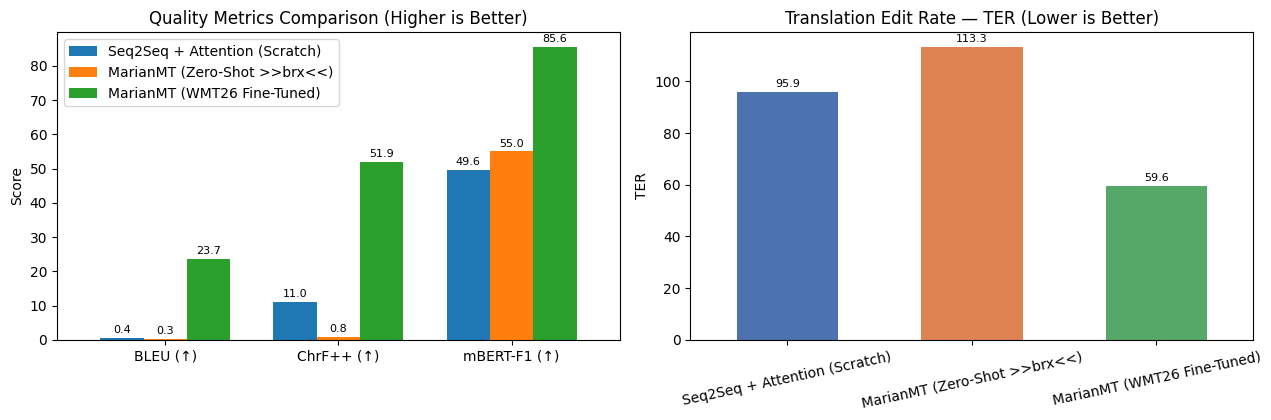

Saved all 500 test translations to 10_bodo_translations.csv

=== Example 1 ===
  English   : The practice of meditation leads to a deeper connection with the self.
  Reference : ध्याननि सोलोंनाया गावजों मोनसे गोथौ सोमोन्दो लाबोयो।
  Seq2Seq   : मोनसे गोहोगोरा
  Zero-Shot : L’enseignement de meditación, illeen tolke demasiado relacione.
  Fine-Tuned: ध्याननि हुदाया गावजों गोथौ सोमोन्दो लाबोयो। 

=== Example 2 ===
  English   : The study of natural events, their causes, and consequences through systematic processes.
  Reference : खान्थियारि खान्थिनि गेजेरजों मिथिंगायारि जाथायफोर, बेफोरनि जाहोनफोर आरो फिथायफोरनि फरायसंनाय।
  Seq2Seq   : बुहुम आरो गेजेरजों मिथिंगायारि जाथायफोरखौ गेजेरजों मिथिंगायारि जाथायफोरखौ नागिरनाय
  Zero-Shot : • studio natural eventos, causas, and consequences per systematic process.
  Fine-Tuned: मिथिंगायारि जाथायफोर, बिसोरनि जाहोनफोर आरो खान्थियारि बिखान्थिफोरनि गेजेरजों फिथायनाय। 

=== Example 3 ===
  English   : Hockey is an intense aerobic activity that increase

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
res_df[['BLEU (↑)', 'ChrF++ (↑)', 'mBERT-F1 (↑)']].T.plot.bar(ax=ax[0], rot=0, width=0.75)
ax[0].set(title='Quality Metrics Comparison (Higher is Better)', ylabel='Score')
for c in ax[0].containers:
    ax[0].bar_label(c, fmt='%.1f', fontsize=8, padding=2)

res_df['TER (↓)'].plot.bar(ax=ax[1], rot=12, color=['#4c72b0', '#dd8452', '#55a868'], width=0.55)
ax[1].set(title='Translation Edit Rate — TER (Lower is Better)', ylabel='TER')
for c in ax[1].containers:
    ax[1].bar_label(c, fmt='%.1f', fontsize=8, padding=2)
plt.tight_layout(); plt.show()

out_df = pd.DataFrame({
    'English_Source': test_df['en'],
    'Bodo_Reference': refs,
    'Seq2Seq_Scratch': hyps_seq2seq,
    'MarianMT_ZeroShot': hyps_zeroshot,
    'MarianMT_FineTuned': hyps_finetuned,
})
out_df.to_csv('10_bodo_translations.csv', index=False, encoding='utf-8-sig')
print('Saved all 500 test translations to 10_bodo_translations.csv\n')

for i in range(3):
    print(f'=== Example {i+1} ===')
    print('  English   :', out_df.loc[i, 'English_Source'])
    print('  Reference :', out_df.loc[i, 'Bodo_Reference'])
    print('  Seq2Seq   :', out_df.loc[i, 'Seq2Seq_Scratch'])
    print('  Zero-Shot :', out_df.loc[i, 'MarianMT_ZeroShot'])
    print('  Fine-Tuned:', out_df.loc[i, 'MarianMT_FineTuned'], '\n')

**Interpretation:**
* **Massive Gains from In-Domain Transfer Learning (`MarianMT` Fine-Tuned):** Fine-tuning `Helsinki-NLP/opus-mt-en-mul` for 4 epochs (`200.9s`) on the WMT 2026 English–Bodo corpus jumps **BLEU from `0.28 → 23.69`**, **ChrF++ from `0.82 → 51.93`**, and **mBERT-F1 from `55.04 → 85.56`**, while cutting **TER nearly in half (`113.35 → 59.64`)**.
* **Why Zero-Shot `>>brx<<` Fails Without Adaptation:** Although `>>brx<<` exists in `opus-mt-en-mul`'s vocabulary, Bodo had virtually negligible parallel data in the original Tatoeba pretraining mix, causing the zero-shot decoder to fall back to high-resource Romance/Latin tokens (*Example 1–3*).
* **From-Scratch Seq2Seq + Attention (`11.01` ChrF++):** With Unicode-aware Devanagari tokenization, the 1-layer GRU + Attention model learns genuine Bodo domain phrases (*मिथिंगायारि जाथायफोर* = 'natural events', *सावस्रिखौ बांहोयो* = 'improves health') in `24.4s`, outperforming zero-shot MarianMT on **ChrF++ (`11.01` vs. `0.82`)** and **TER (`95.95` vs. `113.35`)**, but suffers from word-level OOV sparsity and phrase repetition compared to subword-pretrained Transformer fine-tuning.
* **Why `ChrF++` (`51.93`) Complements `BLEU` (`23.69`) for Bodo:** Because Bodo is an agglutinative Sino-Tibetan language (`हारखौ`, `सावस्रिखौ`, `सोमोन्दो`), minor case-suffix differences zero out 4-gram BLEU matches even when stems match—captured accurately by character-aware **ChrF++** (`51.93`) and contextual **mBERT-F1** (`85.56`).